Import libraries

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile
import requests
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from google.colab import files
from PIL import Image

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow Version: 2.21.0
GPU Available: True


Download the dataset

In [ ]:

import os
import zipfile
import requests

# Alternative dataset URL
dataset_url = "https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip"

zip_path = "/content/cats_and_dogs_filtered.zip"
extract_dir = "/content"

print("Downloading dataset...")

response = requests.get(
    dataset_url,
    timeout=180
)
response.raise_for_status()

with open(zip_path, "wb") as f:
    f.write(response.content)

print("Download completed!")

# Extract dataset
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

base_dir = "/content/cats_and_dogs_filtered"
train_dir = os.path.join(base_dir, "train")
validation_dir = os.path.join(base_dir, "validation")

print("Dataset extracted successfully!")
print("Training directory exists:", os.path.exists(train_dir))
print("Validation directory exists:", os.path.exists(validation_dir))
print("Training classes:", os.listdir(train_dir))


Download completed!
Dataset extracted successfully!
Training directory exists: True
Validation directory exists: True
Training classes: ['cats', 'dogs']


In [ ]:

IMG_SIZE = (160, 160)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = train_ds.class_names
print("Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)


Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Classes: ['cats', 'dogs']


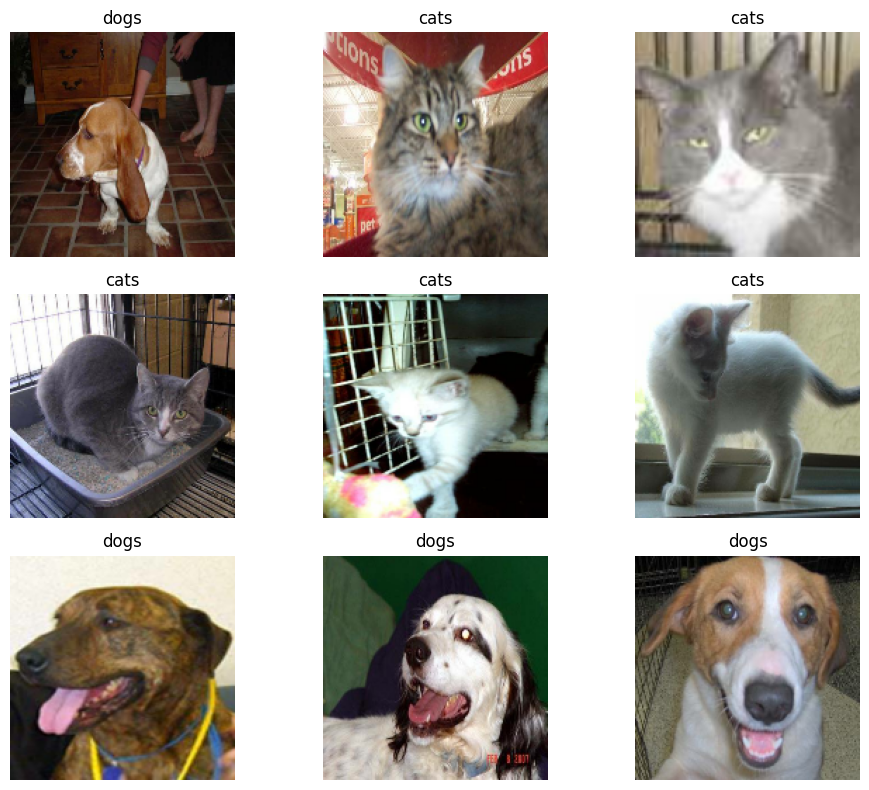

In [ ]:

plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i].numpy()[0])])
        plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

# Load pretrained CNN
base_model = MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained CNN layers
base_model.trainable = False

# Build CNN + ANN classifier
model = models.Sequential([
    layers.Input(shape=(160, 160, 3)),
    layers.Rescaling(1./127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

EPOCHS = 5

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

print("Model training completed!")


Epoch 1/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 27s 231ms/step - accuracy: 0.9580 - loss: 0.1066 - val_accuracy: 0.9850 - val_loss: 0.0407
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.9895 - loss: 0.0306 - val_accuracy: 0.9840 - val_loss: 0.0455
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.9930 - loss: 0.0221 - val_accuracy: 0.9860 - val_loss: 0.0325
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.9950 - loss: 0.0130 - val_accuracy: 0.9850 - val_loss: 0.0384
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.9975 - loss: 0.0077 - val_accuracy: 0.9840 - val_loss: 0.0454
Model training completed!


In [ ]:

loss, accuracy = model.evaluate(val_ds, verbose=1)

print(f"Validation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy * 100:.2f}%")


32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9840 - loss: 0.0454
Validation Loss: 0.0454
Validation Accuracy: 98.40%


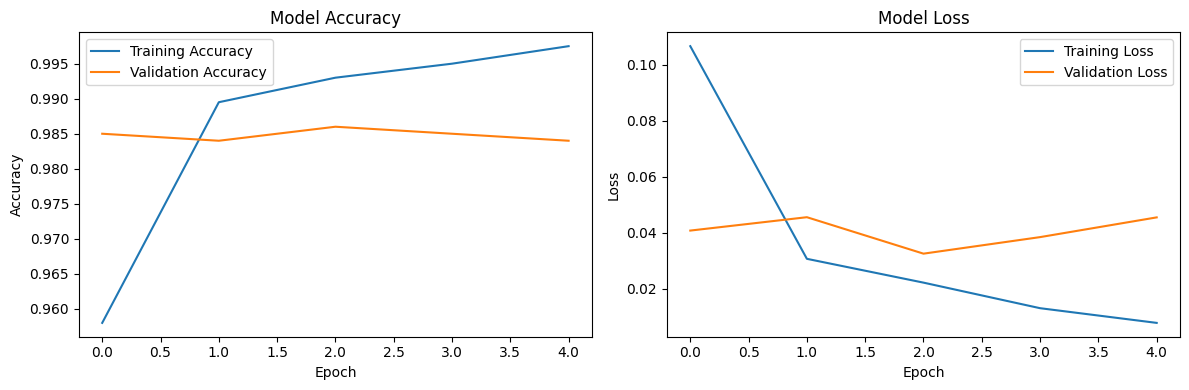

In [ ]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


Saving images.jpeg to images.jpeg


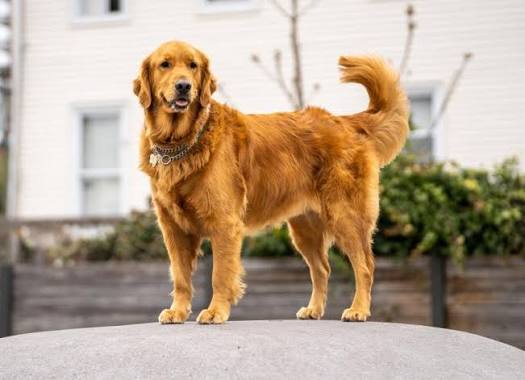

Detected Animal: Dog
Prediction Confidence: 100.00%


In [ ]:

uploaded = files.upload()

for filename in uploaded.keys():
    img = Image.open(filename).convert("RGB")
    display(img)

    img = img.resize(IMG_SIZE)
    img_array = np.array(img, dtype=np.float32)
    img_array = np.expand_dims(img_array, axis=0)

    probability = float(model.predict(img_array, verbose=0)[0][0])

    # The dataset labels are ordered: cat = 0, dog = 1
    if probability >= 0.5:
        prediction = "Dog"
        confidence = probability
    else:
        prediction = "Cat"
        confidence = 1 - probability

    print("Detected Animal:", prediction)
    print(f"Prediction Confidence: {confidence * 100:.2f}%")


In [ ]:

model.save("/content/animal_detection_cnn.keras")

print("Model saved successfully!")

files.download("/content/animal_detection_cnn.keras")


Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>